# NLP — Лабораторная работа №1
## Сентимент-анализ отзывов Кинопоиска: сырой текст → regex → лемматизация

**Вариант 6**

In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# ВАШ ВАРИАНТ (номер по списку группы)
VARIANT = 6

# Логика назначения параметров (не меняйте этот код)
if 1 <= VARIANT <= 5:
    MODEL_CLASS = LogisticRegression
    NGRAMS = (1, 1)
elif 6 <= VARIANT <= 10:
    MODEL_CLASS = LogisticRegression
    NGRAMS = (1, 2)
elif 11 <= VARIANT <= 15:
    MODEL_CLASS = LinearSVC
    NGRAMS = (1, 1)
else:
    raise ValueError("Вариант должен быть от 1 до 15!")

# Уникальное зерно случайности для вашего среза данных
RANDOM_STATE = VARIANT

print(f"Ваш вариант: {VARIANT}")
print(f"Модель для пайплайна: {MODEL_CLASS.__name__}, N-граммы: {NGRAMS}")

Ваш вариант: 6
Модель для пайплайна: LogisticRegression, N-граммы: (1, 2)


## Шаг 1. Загрузка данных и подготовка выборок

In [2]:
import os
import pandas as pd
from datasets import load_dataset

ds = load_dataset("blinoff/kinopoisk", split="train")
df = df = pd.DataFrame(ds)
print("Колонки датасета:", list(df.columns))
df.head(3)

/home/lizaveta/NLP/lab1/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Колонки датасета: ['part', 'movie_name', 'review_id', 'author', 'date', 'title', 'grade3', 'grade10', 'content']


,part,movie_name,review_id,author,date,title,grade3,grade10,content
0,top250,Блеф (1976),17144,Come Back,2011-09-24,Плакали наши денежки ©,Good,10,"\n""Блеф» — одна из моих самых любимых комедий...."
1,top250,Блеф (1976),17139,Stasiki,2008-03-04,NaN,Good,0,\nАдриано Челентано продолжает радовать нас св...
2,top250,Блеф (1976),17137,Flashman,2007-03-04,NaN,Good,10,"\nНесомненно, это один из великих фильмов 80-х..."


In [3]:
TEXT_COL = "content"
GRADE_COL = "grade10"
print(f"текст: '{TEXT_COL}' \nоценка: '{GRADE_COL}'")

df = df[[TEXT_COL, GRADE_COL]].copy()
df.columns = ["content", "grade"]

текст: 'content' 
оценка: 'grade10'


In [4]:
df.head()
dropna_do = len(df)
df = df[df["content"].str.strip() != ""]
print("удалено: ", dropna_do - len(df))

удалено:  0


In [5]:
df["grade"] = pd.to_numeric(df["grade"], errors="coerce")

In [6]:
from sklearn.model_selection import train_test_split


# бинаризируем оценки
df["label"] = df["grade"].apply(lambda x: 1 if x > 5 else 0)

df_sample = df.sample(
    n=min(10000, len(df)), 
    random_state=RANDOM_STATE
    )

X_train, X_test, y_train, y_test = train_test_split(
    df_sample["content"],            
    df_sample["label"],              
    test_size=0.2,                   
    random_state=RANDOM_STATE,       
    stratify=df_sample["label"],     
)

print(f"Размер обучающей выборки: {len(X_train)}")
print(f"Размер тестовой выборки: {len(X_test)}")

Размер обучающей выборки: 8000
Размер тестовой выборки: 2000


## Шаг 2. Универсальная функция для пайплайна

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score
from nltk.corpus import stopwords
import nltk

nltk.download("stopwords", quiet=True)
stop_words = stopwords.words("russian")
# решила удалить, чтобы попробовать увидеть биграммы
# в топе слов, влияющих на настроение текста.
if "не" in stop_words:
    stop_words.remove("не")

def create_pipeline(preprocessor=None):
    """
    Создает sklearn Pipeline для классификации текста.

    :param preprocessor: функция для очистки текста (по умолчанию None - сырой текст)
    :return: объект Pipeline
    """
    pipe = Pipeline([
        ("vectorizer", TfidfVectorizer(
            preprocessor=preprocessor,   # Наша функция очистки (если есть)
            ngram_range=NGRAMS,          # Параметры из варианта (ун/биграммы)
            stop_words=stop_words,       # Русские стоп-слова
        )),
        # Шаг 2: Классификация
        ("classifier", MODEL_CLASS(random_state=RANDOM_STATE)),
    ])
    return pipe


test_pipe = create_pipeline()
print(test_pipe)

Pipeline(steps=[('vectorizer',
                 TfidfVectorizer(ngram_range=(1, 2),
                                 stop_words=['и', 'в', 'во', 'что', 'он', 'на',
                                             'я', 'с', 'со', 'как', 'а', 'то',
                                             'все', 'она', 'так', 'его', 'но',
                                             'да', 'ты', 'к', 'у', 'же', 'вы',
                                             'за', 'бы', 'по', 'только', 'ее',
                                             'мне', 'было', ...])),
                ('classifier', LogisticRegression(random_state=6))])


## Шаг 3. Эксперимент 1 — бейзлайн на «сырых» текстах

In [8]:
pipe_raw = create_pipeline(preprocessor=None)
pipe_raw.fit(X_train, y_train)
y_pred_raw = pipe_raw.predict(X_test)

f1_raw = f1_score(y_test, y_pred_raw)
print(f"F1-score на сырых текстах: {f1_raw:.4f}")

F1-score на сырых текстах: 0.8012


## Шаг 4. Эксперимент 2 — очистка текста (regex)

In [9]:
import re


def clean_text(text):
    # Защита от пустых значений (если вдруг попадется NaN)
    if not isinstance(text, str):
        return ""
    # 1. Нижний регистр
    text = text.lower()
    # 2. Удаляем HTML-теги
    text = re.sub(r"<[^>]+>", " ", text)
    # 3. Удаляем ссылки
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    # 4. Удаляем знаки препинания и цифры (оставляем кириллицу, латиницу и пробелы)
    text = re.sub(r"[^a-zа-яё\s]", " ", text)
    # 5. Убираем лишние пробелы
    text = re.sub(r"\s+", " ", text).strip()
    return text


# Тест на одной строке
sample_text = "Посмотрел <b>фильм</b> вчера в 23:00... Это просто УЖАС!!! Ссылка: http://example.com"
print("До:   ", sample_text)
print("После:", clean_text(sample_text))

До:    Посмотрел <b>фильм</b> вчера в 23:00... Это просто УЖАС!!! Ссылка: http://example.com
После: посмотрел фильм вчера в это просто ужас ссылка


In [10]:
pipe_clean = create_pipeline(preprocessor=clean_text)
pipe_clean.fit(X_train, y_train)
y_pred_clean = pipe_clean.predict(X_test)

f1_clean = f1_score(y_test, y_pred_clean)
print(f"F1-score на очищенных текстах: {f1_clean:.4f}")
print(f"Разница с сырыми текстами: {f1_clean - f1_raw:+.4f}")

F1-score на очищенных текстах: 0.7550
Разница с сырыми текстами: -0.0462


Оценка немного упала. Это произошло из-за слишком жесткой очистки. Мы удалили знаки препинания, а они могут нести достаточно много смысла...

## Шаг 5. Эксперимент 3 — лемматизация (pymorphy3 + lru_cache)

In [11]:
import pymorphy3
from functools import lru_cache

morph = pymorphy3.MorphAnalyzer()


@lru_cache(maxsize=100000)
def get_lemma(word):
    # Берем первую (самую вероятную) лемму
    return morph.parse(word)[0].normal_form


def lemmatize_text(text):
    # 1. Сначала очищаем текст
    text = clean_text(text)
    # 2. Разбиваем на слова
    words = text.split()
    # 3. Лемматизируем каждое слово (через кэш)
    lemmatized_words = [get_lemma(word) for word in words]
    # 4. Склеиваем обратно в строку
    return " ".join(lemmatized_words)


sample = "Коты сидели на подоконниках и смотрели на птиц."
print("До:   ", clean_text(sample))
print("После:", lemmatize_text(sample))

До:    коты сидели на подоконниках и смотрели на птиц
После: кот сидеть на подоконник и смотреть на птица


In [12]:
# Этот шаг самый долгий (от 30 секунд до пары минут)
pipe_lemma = create_pipeline(preprocessor=lemmatize_text)
pipe_lemma.fit(X_train, y_train)
y_pred_lemma = pipe_lemma.predict(X_test)

f1_lemma = f1_score(y_test, y_pred_lemma)
print(f"F1-score на лемматизированных текстах: {f1_lemma:.4f}")
print(f"Разница с очищенными текстами: {f1_lemma - f1_clean:+.4f}")

/home/lizaveta/NLP/lab1/venv/lib/python3.14/site-packages/sklearn/feature_extraction/text.py:412: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['большой', 'весь', 'всё', 'ещё', 'мочь', 'нибыть', 'свой', 'хороший', 'это'] not in stop_words.
  warnings.warn(


F1-score на лемматизированных текстах: 0.7556
Разница с очищенными текстами: +0.0006


оценка немножечко улучшилась, самую малость. Словарь стал компактнее, а модель стала лучше обобщать. Стоит оговориться, что в реальной жизни этот шаг все таки обязателен, даже если бы тут оказалось, что модель стала немного хуже. Дело в том, что лемматизация на больших текстах критически важна

## Шаг 6. Оценка и анализ лучшей модели

In [13]:
# Выбираем лучший этап по F1 автоматически
stages = {
    "1. Сырой текст":            (f1_raw,   y_pred_raw,   pipe_raw),
    "2. Очистка (Regex)":        (f1_clean, y_pred_clean, pipe_clean),
    "3. Лемматизация (pymorphy3)": (f1_lemma, y_pred_lemma, pipe_lemma),
}
best_stage = max(stages, key=lambda k: stages[k][0])
best_f1, best_y_pred, best_pipe = stages[best_stage]

print(f"Лучший этап: {best_stage}")
print(f"Лучшая метрика F1: {best_f1:.4f}")

Лучший этап: 1. Сырой текст
Лучшая метрика F1: 0.8012


In [14]:
print(stages)

{'1. Сырой текст': (0.801189149015236, array([1, 1, 1, ..., 1, 1, 0], shape=(2000,)), Pipeline(steps=[('vectorizer',
                 TfidfVectorizer(ngram_range=(1, 2),
                                 stop_words=['и', 'в', 'во', 'что', 'он', 'на',
                                             'я', 'с', 'со', 'как', 'а', 'то',
                                             'все', 'она', 'так', 'его', 'но',
                                             'да', 'ты', 'к', 'у', 'же', 'вы',
                                             'за', 'бы', 'по', 'только', 'ее',
                                             'мне', 'было', ...])),
                ('classifier', LogisticRegression(random_state=6))])), '2. Очистка (Regex)': (0.7549764748461817, array([1, 1, 1, ..., 1, 1, 0], shape=(2000,)), Pipeline(steps=[('vectorizer',
                 TfidfVectorizer(ngram_range=(1, 2),
                                 preprocessor=<function clean_text at 0x726b30f273d0>,
                                 s

In [15]:
from sklearn.metrics import classification_report

print(classification_report(y_test, best_y_pred, target_names=["Негатив (0)", "Позитив (1)"]))

              precision    recall  f1-score   support

 Негатив (0)       0.91      0.44      0.59       884
 Позитив (1)       0.68      0.97      0.80      1116

    accuracy                           0.73      2000
   macro avg       0.80      0.70      0.70      2000
weighted avg       0.78      0.73      0.71      2000



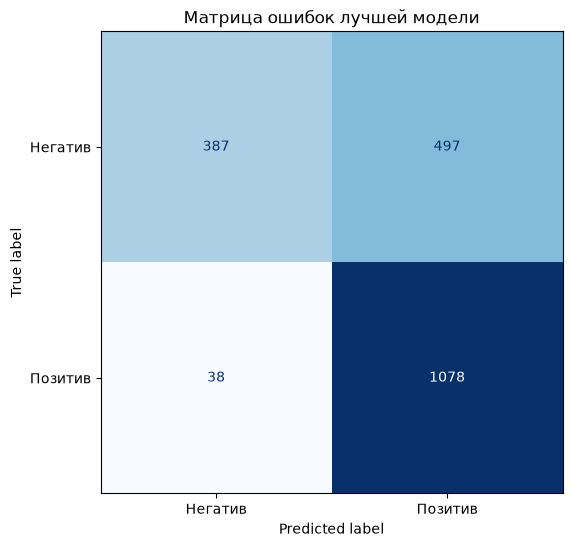

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_y_pred,
    display_labels=["Негатив", "Позитив"],
    ax=ax,
    cmap="Blues",
    colorbar=False,
)
plt.title("Матрица ошибок лучшей модели")
plt.show()

Модель принимает негатив за позитив. Не так частно, но скорее всего это связано с типом отзывов (то, как люди пишут)

In [17]:
import numpy as np

vectorizer = best_pipe.named_steps["vectorizer"]
classifier = best_pipe.named_steps["classifier"]

feature_names = vectorizer.get_feature_names_out()
coefs = classifier.coef_[0]

top_neg_indices = np.argsort(coefs)[:10]
top_pos_indices = np.argsort(coefs)[-10:][::-1]

print("Топ-10 слов, влияющих на НЕГАТИВ (класс 0):")
for idx in top_neg_indices:
    print(f"  {feature_names[idx]}: {coefs[idx]:.3f}")

print("\nТоп-10 слов, влияющих на ПОЗИТИВ (класс 1):")
for idx in top_pos_indices:
    print(f"  {feature_names[idx]}: {coefs[idx]:+.3f}")

Топ-10 слов, влияющих на НЕГАТИВ (класс 0):
  вообще: -1.560
  шутки: -1.417
  снимать: -1.021
  создатели: -0.998
  не: -0.977
  деньги: -0.955
  пародия: -0.950
  понятно: -0.938
  бред: -0.843
  кино: -0.838

Топ-10 слов, влияющих на ПОЗИТИВ (класс 1):
  10: +17.808
  10 10: +11.253
  очень: +2.145
  всё: +1.635
  жизнь: +1.419
  каждый: +1.411
  роли: +1.388
  роль: +1.318
  именно: +1.296
  нужно: +1.292


Мой вариант использует биграммы (1, 2). Однако в топе слов, влияющих на настроение текста есть только одна биграмма - это "10 10". Думаю, что имеется в виду 10/10. такие фразы как не понравился не используются тут, потому что они удаляются в самом начале. Во второй попытке я решила удалить НЕ из stop_words, чтобы посмотреть, как изменятся метрики. они немного улучшились, а частица НЕ появилась в топе слов, влияющих на негатив. Удивительно (для меня), но биграмм с НЕ не появилос (например НЕ ПОНРАВИЛОСЬ)

## Шаг 7. Сводная таблица и выводы

In [18]:
from IPython.display import display

results = pd.DataFrame({
    "Этап обработки": list(stages.keys()),
    "F1-score": [f1_raw, f1_clean, f1_lemma],
    "Размер словаря": [
        len(p.named_steps["vectorizer"].vocabulary_) for p in (pipe_raw, pipe_clean, pipe_lemma)
    ],
})

# Разница относительно сырого текста (в процентных пунктах)
results["Дельта к baseline (%)"] = (results["F1-score"] - f1_raw) * 100

results["F1-score"] = results["F1-score"].round(4)
results["Дельта к baseline (%)"] = results["Дельта к baseline (%)"].round(2)

print("Сводные результаты эксперимента:")
display(results)

Сводные результаты эксперимента:


,Этап обработки,F1-score,Размер словаря,Дельта к baseline (%)
0,1. Сырой текст,0.8012,1235946,0.00
1,2. Очистка (Regex),0.7550,1229203,-4.62
2,3. Лемматизация (pymorphy3),0.7556,881393,-4.56


### Выводы по лабораторной работе

1. Сравнение этапов предобработки. В ходе эксперимента лучший F1-score (0.8012) достигнут на этапе 1. - Сырой текст. 
сырой текст - 0.8012
regex-очистка - 0.7550
лемматизация - 0.7556

Очистка текста регулярными выражениями: F1 снизился на 4.62. Это произошло потому, что словарь сократился, но вместе с шумом удалились цифры и символы, которые несли часть эмоциональной окраски (например, оценки вида "...", "!!!").
Лемматизация: F1 практически не изменился относительно очистки на 0.06 лучше; относительно сырого текста - хуже на 4.56. Это связано с тем, что словарь уменьшился, но на выборке в 10 000 отзывов формы слов повторяются достаточно часто, поэтому модель и без лемматизации справляется почти так же.
2. Анализ ошибок модели. По матрице ошибок лучшей модели на сыром тексте чаще ошибается на классе 0 (негативном): негативные отзывы принимаются за позитивные (497 ошибок против 38 в обратную сторону). Это ошибка типа FP. Думаю, что причина такая - в бывает сарказм и похвала фильму/актёрам при низкой итоговой оценке, а позитивный класс преобладает в данных и модель смещается к нему. Доля позитивных отзывов в тесте - 0.56. Самые негативные признаки: вообще, шутки, снимать, создатели, не; самые позитивные: 10, 10 10, очень, всё, жизнь - странно, но маловато бинаграммов

3. Влияние варианта (вариант № 6). В моём варианте использовалась модель LogisticRegression с N-граммами (1, 2) (униграммы + биграммы). В топе весов есть пары слов: 10 10. Биграммы позволяют модели учитывать устойчивые сочетания, а не только отдельные слова. Частица "не" входит в стоп-слова, потому что я решила проверить, как изменятся метрики, и изменились они немного в лучшую сторону (примерно +0.2 или около того) . Логистическая регрессия - линейная и прозрачная: веса слов можно прочитать напрямую, как в списках выше, и она выдаёт вероятности классов.